# Used Car Price Prediction in India
### Data Science Laboratory Mini-Project | Python, EDA & Regression

**Project type:** Regression-based price estimation  
**Main tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy and Scikit-learn

> **Dataset note:** The included `used_car_data.csv` is a *synthetic educational dataset* generated to resemble Indian used-car listings. It includes deliberate missing values and duplicate rows to demonstrate data cleaning. Model scores and prices are for coursework practice only, not real market valuations.

## Problem statement
Used-car prices depend on several factors, including brand, age, kilometres driven, fuel type, transmission, engine size, ownership and location. This project explores these relationships and trains regression models to estimate a car's listed price.

## Objectives
1. Load and inspect a dataset with Pandas.
2. Clean data, examine missing values and duplicates, and create a car-age feature.
3. Perform exploratory data analysis (EDA) with statistical summaries and graphs.
4. Apply a simple hypothesis test to compare two fuel-type groups.
5. Train and compare Linear Regression and Random Forest Regression.
6. Evaluate the models using MAE, RMSE, R² and MAPE, then demonstrate a sample prediction.

## Syllabus alignment
The workflow addresses Python data tools, CSV acquisition, missing-value/duplicate handling, visualization and EDA, correlation analysis, hypothesis testing, regression algorithms, model evaluation and mini-project reporting/presentation.

## 1. Import libraries and set reproducibility options
Run the notebook from the extracted project folder. If a library is missing in your environment, install packages from `requirements.txt` first.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

RANDOM_STATE = 42
CURRENT_YEAR = pd.Timestamp.today().year
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn is ready.")
print("Reference year for car age:", CURRENT_YEAR)

Pandas: 2.2.3
NumPy: 2.3.5
Scikit-learn is ready.
Reference year for car age: 2026


## 2. Load the CSV dataset
The notebook searches for `used_car_data.csv` in the current folder and its subfolders, so it can also run after extraction into a project folder.

In [2]:
DATA_PATH = Path("used_car_data.csv")
if not DATA_PATH.exists():
    matches = list(Path.cwd().rglob("used_car_data.csv"))
    if matches:
        DATA_PATH = matches[0]
    else:
        raise FileNotFoundError(
            "Cannot find used_car_data.csv. Extract the project ZIP and run this notebook from the project folder."
        )

raw_df = pd.read_csv(DATA_PATH)
print("Loaded file:", DATA_PATH.resolve())
print("Dataset shape (rows, columns):", raw_df.shape)
display(raw_df.head())

Loaded file: /mnt/data/Used_Car_Price_Prediction_Project/used_car_data.csv
Dataset shape (rows, columns): (1614, 15)


,Car_ID,Brand,Model_Category,Year,Kms_Driven,Fuel_Type,Transmission,Owner,Mileage_kmpl,Engine_CC,Max_Power_BHP,Seats,City,Seller_Type,Selling_Price_INR
0,CAR00001,Honda,Sedan,2019.0,16361.0,Petrol,Manual,Second Owner,15.0,NaN,130.5,4.0,Chennai,Individual,525000.0
1,CAR00002,BMW,Luxury,2016.0,134453.0,Petrol,Manual,First Owner,16.8,2238.0,365.4,5.0,Bengaluru,Dealer,2870000.0
2,CAR00003,Toyota,MPV,2022.0,63267.0,Diesel,Manual,Second Owner,NaN,2470.0,119.9,5.0,Pune,Dealer,1539000.0
3,CAR00004,Volkswagen,Hatchback,2009.0,110695.0,Diesel,Automatic,First Owner,19.5,1065.0,63.6,5.0,Pune,Individual,146000.0
4,CAR00005,Renault,MPV,2021.0,130275.0,Diesel,Manual,First Owner,19.5,2210.0,159.0,5.0,Hyderabad,Individual,567000.0


## 3. Understand the data
`Selling_Price_INR` is the target variable. Other columns describe the vehicle and its listing context.

In [3]:
data_dictionary = pd.DataFrame({
    "Column": ["Car_ID", "Brand", "Model_Category", "Year", "Kms_Driven", "Fuel_Type", "Transmission", "Owner", "Mileage_kmpl", "Engine_CC", "Max_Power_BHP", "Seats", "City", "Seller_Type", "Selling_Price_INR"],
    "Description": [
        "Unique record identifier (not used for prediction)", "Manufacturer brand", "Broad vehicle category", "Manufacturing year",
        "Distance driven in kilometres", "Fuel/energy type", "Manual or automatic gearbox", "Previous-owner category",
        "Approximate fuel mileage in km/litre (0 for electric entries)", "Engine/motor-size proxy in cc-like units (electric entries use a simple class proxy)",
        "Approximate maximum power in bhp", "Number of seats", "Listing city", "Seller category", "Target selling price in Indian rupees"
    ]
})
display(data_dictionary)
print("\nData types:")
display(raw_df.dtypes.rename("dtype").to_frame())

,Column,Description
0,Car_ID,Unique record identifier (not used for predict...
1,Brand,Manufacturer brand
2,Model_Category,Broad vehicle category
3,Year,Manufacturing year
4,Kms_Driven,Distance driven in kilometres
5,Fuel_Type,Fuel/energy type
6,Transmission,Manual or automatic gearbox
7,Owner,Previous-owner category
8,Mileage_kmpl,Approximate fuel mileage in km/litre (0 for el...
9,Engine_CC,Engine/motor-size proxy in cc-like units (elec...



Data types:


,dtype
Car_ID,object
Brand,object
Model_Category,object
Year,float64
Kms_Driven,float64
Fuel_Type,object
Transmission,object
Owner,object
Mileage_kmpl,float64
Engine_CC,float64


## 4. Data quality audit
Check missing values, duplicates and summary statistics before cleaning.

In [4]:
quality_report = pd.DataFrame({
    "Missing_Count": raw_df.isna().sum(),
    "Missing_Percent": (raw_df.isna().mean() * 100).round(2),
    "Data_Type": raw_df.dtypes.astype(str)
}).sort_values("Missing_Percent", ascending=False)
display(quality_report)
print("Exact duplicate rows:", int(raw_df.duplicated().sum()))
display(raw_df.describe(include="all").T)

,Missing_Count,Missing_Percent,Data_Type
Mileage_kmpl,57,3.53,float64
Engine_CC,29,1.80,float64
Max_Power_BHP,28,1.73,float64
Kms_Driven,24,1.49,float64
Brand,19,1.18,object
Seats,16,0.99,float64
Year,16,0.99,float64
City,16,0.99,object
Model_Category,13,0.81,object
Fuel_Type,12,0.74,object


Exact duplicate rows: 14


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_ID,1614,1600,CAR01433,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,1595,14,Maruti,286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model_Category,1601,6,Hatchback,525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,1598.0,NaN,NaN,NaN,2016.16771,4.72308,2005.0,2013.0,2017.0,2020.0,2024.0
Kms_Driven,1590.0,NaN,NaN,NaN,123329.181761,66368.814999,2586.0,71022.75,112556.0,168518.75,260000.0
Fuel_Type,1602,5,Petrol,845,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,1614,2,Manual,1118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,1614,4,First Owner,1076,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mileage_kmpl,1557.0,NaN,NaN,NaN,17.198844,3.695886,0.0,15.3,17.3,19.3,30.0
Engine_CC,1585.0,NaN,NaN,NaN,1548.600631,607.018473,55.0,1109.0,1437.0,1893.0,3822.0


## 5. Clean and prepare the dataset
Cleaning steps: remove exact duplicates, standardize text fields, convert the target to numeric, discard records with missing/non-positive target values, and remove clearly invalid numeric values. Missing *predictor* values are retained here and imputed inside each modelling pipeline to avoid train/test data leakage.

In [5]:
df = raw_df.copy()
initial_rows = len(df)

# Remove exact duplicate records.
df = df.drop_duplicates().copy()
rows_after_dedup = len(df)

# Clean categorical text without replacing valid missing values prematurely.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

# Make sure the target is numeric; a record without a usable target cannot train a supervised model.
df["Selling_Price_INR"] = pd.to_numeric(df["Selling_Price_INR"], errors="coerce")
df = df[df["Selling_Price_INR"].notna() & (df["Selling_Price_INR"] > 0)].copy()

# Filter values that are physically invalid while retaining missing values for imputation.
if "Year" in df:
    df = df[df["Year"].isna() | ((df["Year"] >= 1995) & (df["Year"] <= CURRENT_YEAR + 1))]
for col in ["Kms_Driven", "Mileage_kmpl", "Engine_CC", "Max_Power_BHP", "Seats"]:
    if col in df:
        df = df[df[col].isna() | (df[col] >= 0)]

# Feature engineering: current age of a car in years.
df["Car_Age"] = (CURRENT_YEAR - df["Year"]).clip(lower=0)

df = df.reset_index(drop=True)
print(f"Rows at start: {initial_rows:,}")
print(f"Duplicates removed: {initial_rows - rows_after_dedup:,}")
print(f"Rows after target/validity checks: {len(df):,}")
print("Remaining missing cells:", int(df.isna().sum().sum()))
display(df.head())

Rows at start: 1,614
Duplicates removed: 14
Rows after target/validity checks: 1,594
Remaining missing cells: 253


,Car_ID,Brand,Model_Category,Year,Kms_Driven,Fuel_Type,Transmission,Owner,Mileage_kmpl,Engine_CC,Max_Power_BHP,Seats,City,Seller_Type,Selling_Price_INR,Car_Age
0,CAR00001,Honda,Sedan,2019.0,16361.0,Petrol,Manual,Second Owner,15.0,NaN,130.5,4.0,Chennai,Individual,525000.0,7.0
1,CAR00002,BMW,Luxury,2016.0,134453.0,Petrol,Manual,First Owner,16.8,2238.0,365.4,5.0,Bengaluru,Dealer,2870000.0,10.0
2,CAR00003,Toyota,MPV,2022.0,63267.0,Diesel,Manual,Second Owner,NaN,2470.0,119.9,5.0,Pune,Dealer,1539000.0,4.0
3,CAR00004,Volkswagen,Hatchback,2009.0,110695.0,Diesel,Automatic,First Owner,19.5,1065.0,63.6,5.0,Pune,Individual,146000.0,17.0
4,CAR00005,Renault,MPV,2021.0,130275.0,Diesel,Manual,First Owner,19.5,2210.0,159.0,5.0,Hyderabad,Individual,567000.0,5.0


### Detect potential price outliers with the IQR method
Price outliers are flagged for inspection rather than automatically deleted. A high price may be legitimate for a premium-brand vehicle.

In [6]:
q1 = df["Selling_Price_INR"].quantile(0.25)
q3 = df["Selling_Price_INR"].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr
price_outliers = df[(df["Selling_Price_INR"] < lower_bound) | (df["Selling_Price_INR"] > upper_bound)]
print(f"IQR lower bound: ₹{lower_bound:,.0f}")
print(f"IQR upper bound: ₹{upper_bound:,.0f}")
print(f"Potential price outliers flagged: {len(price_outliers):,} ({len(price_outliers)/len(df):.1%})")

IQR lower bound: ₹0
IQR upper bound: ₹1,348,875
Potential price outliers flagged: 121 (7.6%)


## 6. Exploratory Data Analysis (EDA)
The next charts explore the target distribution, price patterns by category and relationships among numeric variables.

In [7]:
# Create an EDA-only copy with readable labels filled for plots. The modelling pipeline imputes separately.
eda_df = df.copy()
eda_numeric = ["Car_Age", "Kms_Driven", "Mileage_kmpl", "Engine_CC", "Max_Power_BHP", "Seats"]
eda_categorical = ["Brand", "Model_Category", "Fuel_Type", "Transmission", "Owner", "City", "Seller_Type"]
for col in eda_numeric:
    eda_df[col] = eda_df[col].fillna(eda_df[col].median())
for col in eda_categorical:
    if eda_df[col].notna().any():
        eda_df[col] = eda_df[col].fillna(eda_df[col].mode().iloc[0])
    else:
        eda_df[col] = eda_df[col].fillna("Unknown")

print("Target descriptive statistics (INR):")
display(eda_df["Selling_Price_INR"].describe().to_frame().T)

Target descriptive statistics (INR):


,count,mean,std,min,25%,50%,75%,max
Selling_Price_INR,1594.0,591941.656211,883009.219426,65000.0,187000.0,336000.0,651750.0,10735000.0


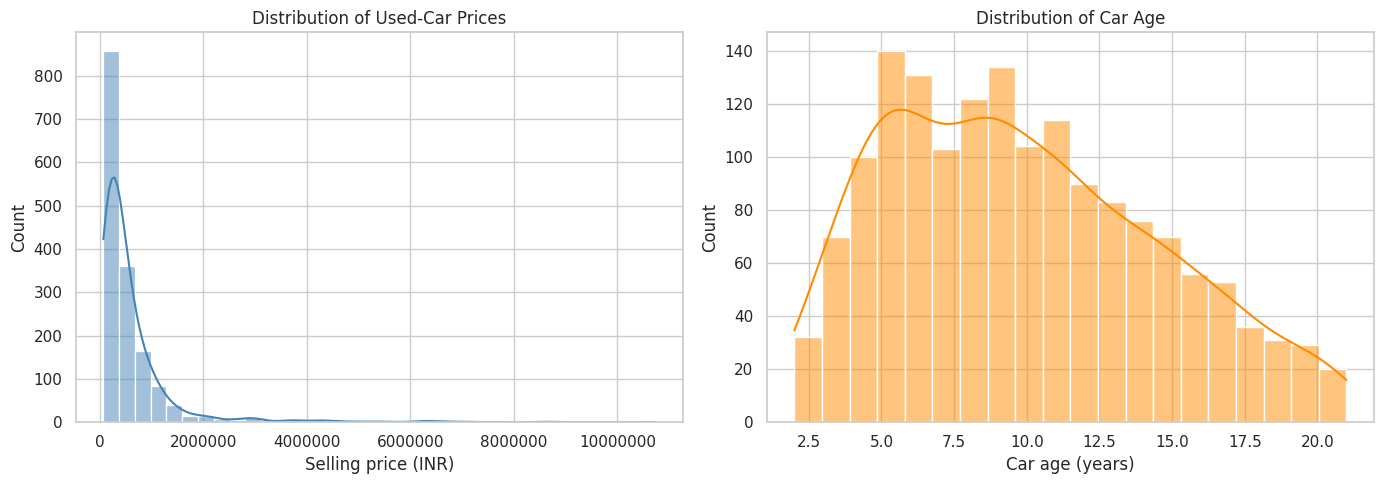

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(eda_df["Selling_Price_INR"], bins=35, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of Used-Car Prices")
axes[0].set_xlabel("Selling price (INR)")
axes[0].ticklabel_format(style="plain", axis="x")
sns.histplot(eda_df["Car_Age"], bins=20, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Distribution of Car Age")
axes[1].set_xlabel("Car age (years)")
plt.tight_layout()
plt.show()

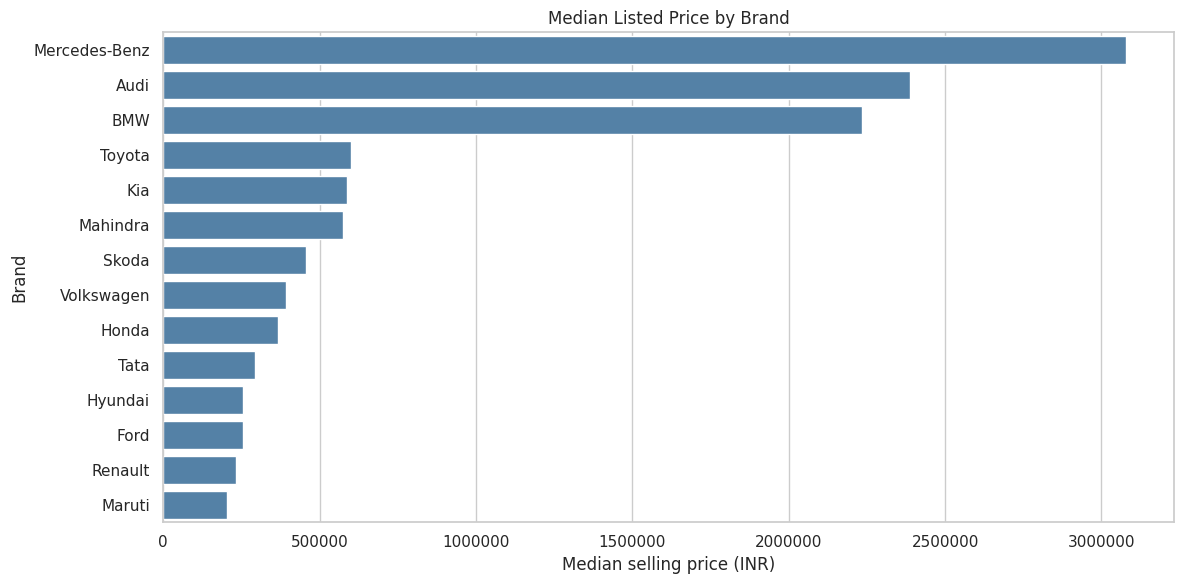

,Brand,Selling_Price_INR
8,Mercedes-Benz,3078000.0
0,Audi,2387500.0
1,BMW,2235000.0
12,Toyota,599500.0
5,Kia,586500.0
6,Mahindra,575000.0
10,Skoda,457000.0
13,Volkswagen,392500.0
3,Honda,367000.0
11,Tata,292000.0


In [9]:
brand_prices = eda_df.groupby("Brand", as_index=False)["Selling_Price_INR"].median().sort_values("Selling_Price_INR", ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(data=brand_prices, x="Selling_Price_INR", y="Brand", color="steelblue")
plt.title("Median Listed Price by Brand")
plt.xlabel("Median selling price (INR)")
plt.ylabel("Brand")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()
display(brand_prices.assign(Selling_Price_INR=brand_prices["Selling_Price_INR"].round(0)))

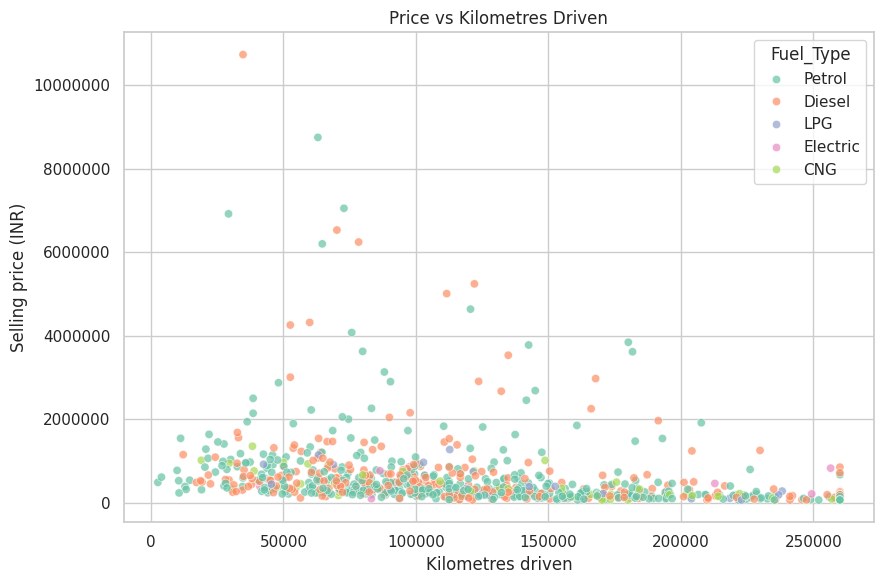

In [10]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=eda_df.sample(min(800, len(eda_df)), random_state=RANDOM_STATE), x="Kms_Driven", y="Selling_Price_INR", hue="Fuel_Type", palette="Set2", alpha=0.7)
plt.title("Price vs Kilometres Driven")
plt.xlabel("Kilometres driven")
plt.ylabel("Selling price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

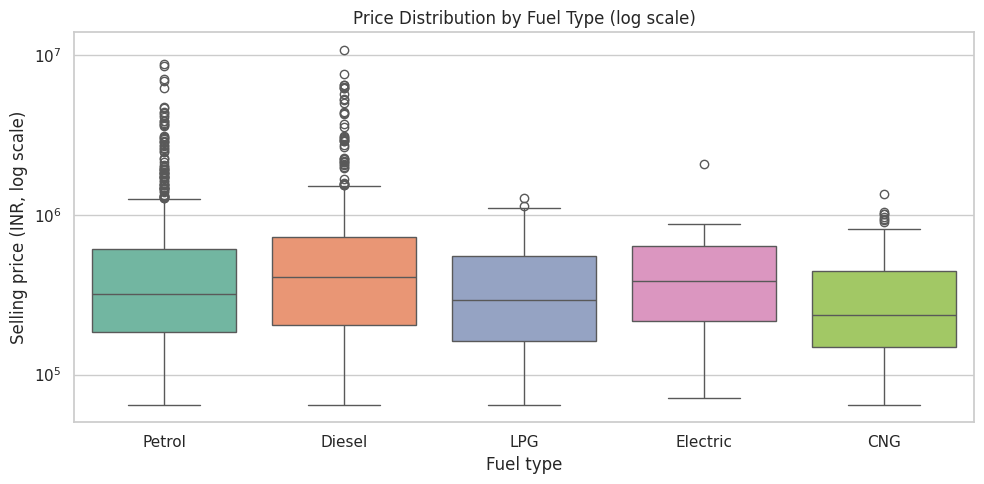

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=eda_df, x="Fuel_Type", y="Selling_Price_INR", palette="Set2", hue="Fuel_Type", legend=False)
plt.yscale("log")
plt.title("Price Distribution by Fuel Type (log scale)")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (INR, log scale)")
plt.tight_layout()
plt.show()

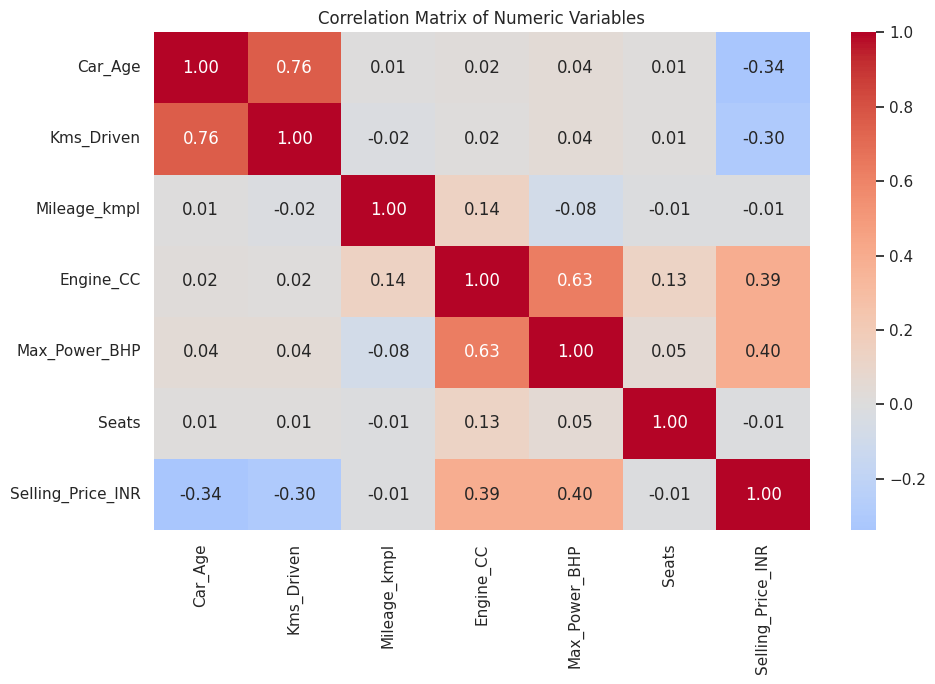

,Correlation with price
Selling_Price_INR,1.000000
Max_Power_BHP,0.398733
Engine_CC,0.391089
Mileage_kmpl,-0.012949
Seats,-0.013199
Kms_Driven,-0.296292
Car_Age,-0.337577


In [12]:
correlation_columns = ["Car_Age", "Kms_Driven", "Mileage_kmpl", "Engine_CC", "Max_Power_BHP", "Seats", "Selling_Price_INR"]
correlation_matrix = eda_df[correlation_columns].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()
display(correlation_matrix["Selling_Price_INR"].sort_values(ascending=False).to_frame("Correlation with price"))

## 7. Simple hypothesis test
**Question:** In this dataset, is the average listed price different between petrol and diesel cars?  
**Null hypothesis (H₀):** The population mean price is equal for the Petrol and Diesel groups.  
**Alternative hypothesis (H₁):** The population mean prices differ.  
We use Welch's independent two-sample t-test, which does not assume equal group variances. This is an observational comparison and does not prove fuel type alone causes a price difference.

In [13]:
petrol_prices = df.loc[df["Fuel_Type"] == "Petrol", "Selling_Price_INR"].dropna()
diesel_prices = df.loc[df["Fuel_Type"] == "Diesel", "Selling_Price_INR"].dropna()
if len(petrol_prices) >= 2 and len(diesel_prices) >= 2:
    t_stat, p_value = stats.ttest_ind(petrol_prices, diesel_prices, equal_var=False)
    print(f"Petrol cars: n={len(petrol_prices)}, mean=₹{petrol_prices.mean():,.0f}")
    print(f"Diesel cars: n={len(diesel_prices)}, mean=₹{diesel_prices.mean():,.0f}")
    print(f"Welch t-statistic = {t_stat:.3f}")
    print(f"p-value = {p_value:.6f}")
    if p_value < 0.05:
        print("Decision at 5% significance: reject H0; the sample provides evidence of a mean-price difference.")
    else:
        print("Decision at 5% significance: fail to reject H0; there is insufficient evidence of a mean-price difference.")
else:
    print("Not enough Petrol and Diesel observations for the test.")

Petrol cars: n=836, mean=₹572,925
Diesel cars: n=566, mean=₹690,680
Welch t-statistic = -2.240
p-value = 0.025299
Decision at 5% significance: reject H0; the sample provides evidence of a mean-price difference.


## 8. Prepare features for regression
We predict `Selling_Price_INR`. `Car_ID` is an identifier and is excluded. `Year` is represented through the engineered `Car_Age` feature. Numeric missing values are imputed with the median; categorical missing values are imputed with the most frequent category, and categories are one-hot encoded.

### Mathematical background
A linear regression model estimates price as a weighted sum of the input features:

\[
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p
\]

The Random Forest Regressor averages predictions from many decision trees and can capture nonlinear relationships. Model performance is compared on a held-out test set not used during fitting.

In [14]:
TARGET = "Selling_Price_INR"
NUMERIC_FEATURES = ["Car_Age", "Kms_Driven", "Mileage_kmpl", "Engine_CC", "Max_Power_BHP", "Seats"]
CATEGORICAL_FEATURES = ["Brand", "Model_Category", "Fuel_Type", "Transmission", "Owner", "City", "Seller_Type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, NUMERIC_FEATURES),
    ("cat", categorical_transformer, CATEGORICAL_FEATURES)
])

print("Input feature count:", len(FEATURES))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Input feature count: 13
Training rows: 1275
Testing rows: 319


## 9. Train and compare regression models
We compare Linear Regression (baseline) with Random Forest Regression (nonlinear ensemble). MAE and RMSE are in rupees; R² is a unitless goodness-of-fit metric; MAPE expresses average absolute error as a percentage of actual price.

In [15]:
models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=180,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    denominator = np.maximum(np.asarray(y_true, dtype=float), 1.0)
    mape = np.mean(np.abs((np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)) / denominator)) * 100
    return {"MAE (₹)": mae, "RMSE (₹)": rmse, "R²": r2, "MAPE (%)": mape}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {"Model": name, **calculate_metrics(y_test, pred)}
    results.append(row)

results_df = pd.DataFrame(results).sort_values("RMSE (₹)").reset_index(drop=True)
print("Model comparison on held-out test data:")
display(results_df.style.format({"MAE (₹)": "₹{:,.0f}", "RMSE (₹)": "₹{:,.0f}", "R²": "{:.3f}", "MAPE (%)": "{:.2f}%"}))
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]
best_predictions = predictions[best_model_name]
print("Selected model (lowest test RMSE):", best_model_name)

Model comparison on held-out test data:


,Model,MAE (₹),RMSE (₹),R²,MAPE (%)
0,Random Forest,"₹132,508","₹300,967",0.883,23.87%
1,Linear Regression,"₹232,635","₹436,042",0.754,79.33%


Selected model (lowest test RMSE): Random Forest


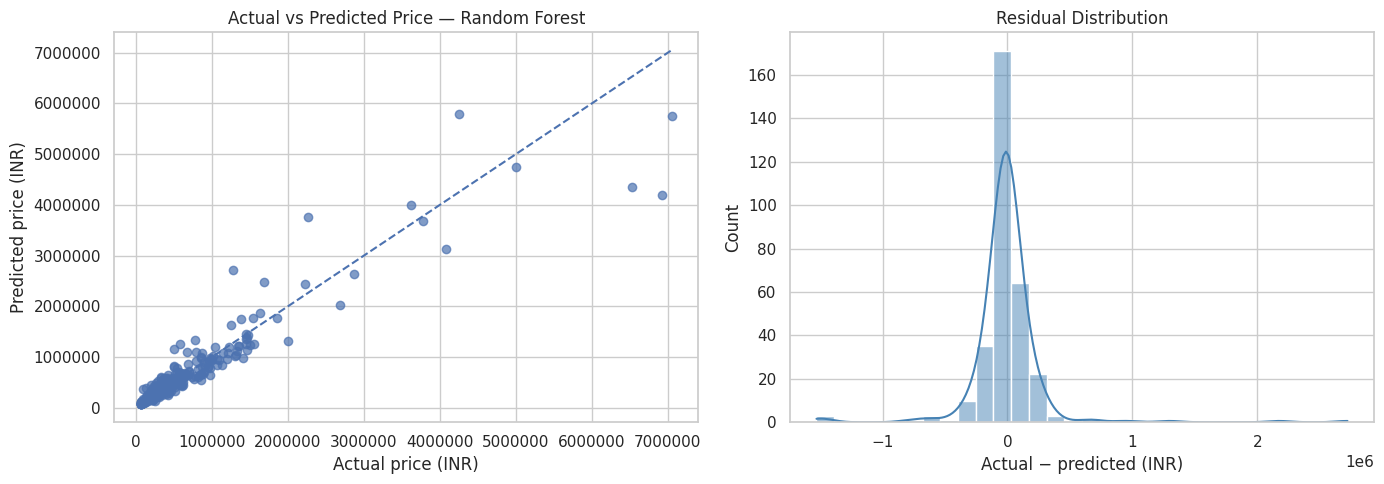

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, best_predictions, alpha=0.7)
min_v = min(y_test.min(), best_predictions.min())
max_v = max(y_test.max(), best_predictions.max())
axes[0].plot([min_v, max_v], [min_v, max_v], linestyle="--")
axes[0].set_title(f"Actual vs Predicted Price — {best_model_name}")
axes[0].set_xlabel("Actual price (INR)")
axes[0].set_ylabel("Predicted price (INR)")
axes[0].ticklabel_format(style="plain")
residuals = y_test.to_numpy() - best_predictions
sns.histplot(residuals, bins=30, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Actual − predicted (INR)")
plt.tight_layout()
plt.show()

## 10. Cross-validation for a more robust estimate
Cross-validation trains/evaluates the selected pipeline over multiple train/validation splits. Its score may differ from the single held-out test result.

In [17]:
cv_scores = cross_val_score(
    best_model, X, y,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)
cv_mae = -cv_scores
print("3-fold cross-validation MAE scores (₹):", np.round(cv_mae, 0))
print(f"Mean CV MAE: ₹{cv_mae.mean():,.0f} ± ₹{cv_mae.std():,.0f}")

3-fold cross-validation MAE scores (₹): [161887. 113291. 152649.]
Mean CV MAE: ₹142,609 ± ₹21,071


## 11. Understand Random Forest feature importance
Feature importance is taken from the fitted Random Forest model. It is a model-based indicator of predictive usefulness, not proof of causation. One-hot encoded categories appear as individual features.

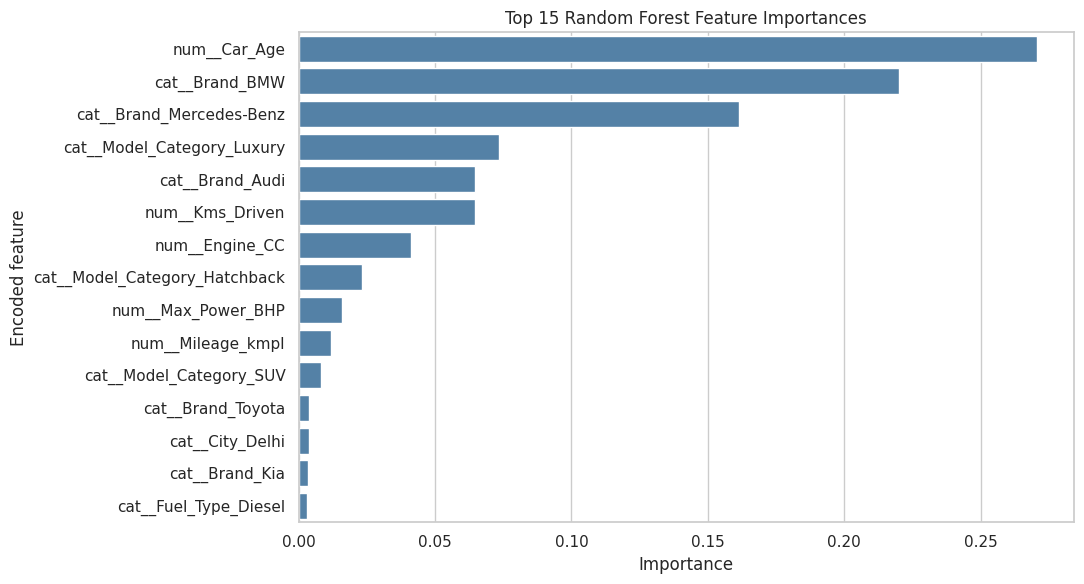

,Feature,Importance
0,num__Car_Age,0.270702
1,cat__Brand_BMW,0.220075
2,cat__Brand_Mercedes-Benz,0.161455
3,cat__Model_Category_Luxury,0.073593
4,cat__Brand_Audi,0.064668
5,num__Kms_Driven,0.064649
6,num__Engine_CC,0.041217
7,cat__Model_Category_Hatchback,0.023402
8,num__Max_Power_BHP,0.015844
9,num__Mileage_kmpl,0.011708


In [18]:
rf_pipeline = models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

plt.figure(figsize=(11, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", color="steelblue")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()
display(importance_df.reset_index(drop=True))

## 12. Predict the price of a sample car
The example values below can be changed. The output is an estimate from the best-performing model selected above; because training data is synthetic, the prediction is only for demonstrating the workflow.

In [19]:
sample_car = pd.DataFrame([{
    "Car_Age": 5,
    "Kms_Driven": 55000,
    "Mileage_kmpl": 18.0,
    "Engine_CC": 1497,
    "Max_Power_BHP": 100.0,
    "Seats": 5,
    "Brand": "Hyundai",
    "Model_Category": "Sedan",
    "Fuel_Type": "Petrol",
    "Transmission": "Manual",
    "Owner": "First Owner",
    "City": "Pune",
    "Seller_Type": "Individual"
}])[FEATURES]
sample_price = float(best_model.predict(sample_car)[0])
print("Sample car details:")
display(sample_car)
print(f"Estimated selling price: ₹{sample_price:,.0f}")

Sample car details:


,Car_Age,Kms_Driven,Mileage_kmpl,Engine_CC,Max_Power_BHP,Seats,Brand,Model_Category,Fuel_Type,Transmission,Owner,City,Seller_Type
0,5,55000,18.0,1497,100.0,5,Hyundai,Sedan,Petrol,Manual,First Owner,Pune,Individual


Estimated selling price: ₹622,860


### Try your own values
Edit the values in this cell and run it again. Choose categories that appear in the included dataset, though the pipeline can handle an unseen category.

In [20]:
def predict_used_car_price(car_age, kms_driven, mileage_kmpl, engine_cc, max_power_bhp,
                           seats, brand, model_category, fuel_type, transmission,
                           owner, city, seller_type):
    """Predict a used-car price in INR using the selected fitted pipeline."""
    one_car = pd.DataFrame([{
        "Car_Age": car_age,
        "Kms_Driven": kms_driven,
        "Mileage_kmpl": mileage_kmpl,
        "Engine_CC": engine_cc,
        "Max_Power_BHP": max_power_bhp,
        "Seats": seats,
        "Brand": brand,
        "Model_Category": model_category,
        "Fuel_Type": fuel_type,
        "Transmission": transmission,
        "Owner": owner,
        "City": city,
        "Seller_Type": seller_type
    }])[FEATURES]
    return float(best_model.predict(one_car)[0])

custom_estimate = predict_used_car_price(
    car_age=4,
    kms_driven=42000,
    mileage_kmpl=17.5,
    engine_cc=1197,
    max_power_bhp=88.0,
    seats=5,
    brand="Maruti",
    model_category="Hatchback",
    fuel_type="Petrol",
    transmission="Manual",
    owner="First Owner",
    city="Pune",
    seller_type="Individual"
)
print(f"Custom sample estimate: ₹{custom_estimate:,.0f}")

Custom sample estimate: ₹351,493


## 13. Save the trained model
The saved file contains the entire preprocessing + regression pipeline, so it can be reused without separately rebuilding the encoders.

In [21]:
MODEL_PATH = Path("best_used_car_price_model.joblib")
joblib.dump(best_model, MODEL_PATH)
print("Saved fitted model to:", MODEL_PATH.resolve())
print("Model file size:", f"{MODEL_PATH.stat().st_size / 1024:.1f} KB")

Saved fitted model to: /mnt/data/Used_Car_Price_Prediction_Project/best_used_car_price_model.joblib
Model file size: 8790.1 KB


## 14. Conclusion
Use the metric table and graphs generated by your run when writing the final result. Do not copy pre-assumed scores: the exact metrics depend on the included data, the Python/Scikit-learn version, and the train/test split.

**Conclusion checklist:**
- State which model had the lower test RMSE and report MAE, RMSE, R² and MAPE.
- Mention the strongest visible price relationships from EDA and feature importance.
- Describe the number of duplicate rows removed, remaining missing fields and the imputation approach.
- Report the hypothesis-test p-value and the decision at the 5% significance level.
- Mention that the dataset is synthetic and predictions are not real market valuations.

## Limitations and future scope
1. The included dataset is synthetic; validate the model on licensed, real used-car listings before making market claims.
2. Price depends on condition, accident history, service records, variant, local demand and negotiation, which are not fully represented here.
3. Future work can use a real CarDekho dataset, tune hyperparameters, perform richer cross-validation and build a Streamlit interface.

## Syllabus alignment summary
| Syllabus area | Demonstrated in this notebook |
|---|---|
| Data Science tools and Python basics | Imports, Pandas, NumPy and notebook workflow |
| Data acquisition and cleaning | CSV loading, schema inspection, duplicates, missing values, validity filters |
| Data visualization and EDA | Histograms, bar plot, scatter plot, box plot, correlation heatmap |
| Statistical / algorithmic modelling | Welch t-test, Linear Regression, Random Forest Regression |
| Model evaluation | MAE, RMSE, R², MAPE and 3-fold cross-validation |
| Mini-project report | Problem statement, data dictionary, mathematical background, conclusion and limitations |